**ANOMALY DETECTION OC-SVM**

In [3]:
import digitalhub as dh
import zipfile
import json
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

PROJECT_NAME = "floods"
project = dh.get_project(PROJECT_NAME)
print(f"Project: {project.name}")

Project: floods


**SETUP PARAMETERS**

In [81]:
job_name = "attn_0per_w"
dataset_standard = "Standard"
dataset_anomalies = "Floods_Anomalies_v3_crop_norm"
moco_version = "v2"

parameters = {
    "job_name": job_name,                          
    "dataset_standard": dataset_standard,
    "dataset_anomalies": dataset_anomalies,         
    "moco_version": moco_version, 
    "old_vectors": "", 
    "ocsvm_nu": 0.05,                       
    "ocsvm_gamma": "scale", 
    "min_flood_area": 0.0,
    "moco_attn": True,                 
    
    "simple_proj": False,                          
    "attn": False,                                  
    "hidden_channels_dim": 64,
    "pool_grid": 4,
    "moco_dim": 128,
    "moco_k": 4096,
    "moco_m": 0.999,
    "moco_t": 0.07,
    "patch_size": 256,
    "n_images1": 4, "n_channels1": 2,       # sar
    "n_images2": 4, "n_channels2": 10,      # ottico       
    "standardize": True,                    
    "batch_size": 16,
    "workers": 0,
}

volumes = [
    {
        "volume_type": "ephemeral",
        "name": "volume-spazio-dati",
        "mount_path": "/data",
        "spec": {"size": "200Gi"}
    }
]

**BUILD ENVIRONMENT**

In [82]:
ocsvm_func = project.new_function(
    name=f'ocsvm_w',
    kind="python",
    python_version="PYTHON3_10",
    code_src="../src/",
    handler="anomaly:ad_ocsvm",
    image="harbor.atlas.fbk.eu/rsde/rsde-platform-floods-floodsimagev3:9b7e2",
)

**TRAINING**

In [ ]:
resources = {"cpu": "4"}

run_ad = ocsvm_func.run(
    action="job",
    parameters=parameters,
    volumes=volumes,
    resources = resources,
    profile="1xv100-shared",
    local_execution=False,
    wait=True
)

print(f"Run anomaly detection ocsvm: {run_ad.id}")

2026-10-23 13:24:07,798 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 4348142dbc754100a790ced0d0286894 to finish...
2026-10-23 13:24:12,807 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 4348142dbc754100a790ced0d0286894 to finish...
2026-10-23 13:24:17,816 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 4348142dbc754100a790ced0d0286894 to finish...
2026-10-23 13:24:22,828 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 4348142dbc754100a790ced0d0286894 to finish...
2026-10-23 13:24:27,840 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 4348142dbc754100a790ced0d0286894 to finish...
2026-10-23 13:24:32,849 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 4348142dbc754100a790ced0d0286894 to finish...
2026-10-23 13:24:37,861 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 4348142dbc754100a790ced0d0286894 to finish...
2026-10-23 13

In [ ]:
RESULTS_DIR = "/tmp/anomaly_results_ocsvm"

zip_path = project.get_artifact(f"anomaly_results_ocsvm_{job_name}").download("/tmp/anomaly_results_ocsvm.zip", overwrite=True)
with zipfile.ZipFile(zip_path) as z:
    z.extractall(RESULTS_DIR)
with open(f"{RESULTS_DIR}/anomaly_results.json") as f:
    results = json.load(f)

df = pd.read_csv(f"{RESULTS_DIR}/scores.csv")                    
score_normal = df[df.label == 0]['score']
score_anom = df[df.label == 1]['score']

print(f"n_fit: {results['n_fit']} | n_thr: {results['n_thr']} | n_normali: {results['n_normali']} | n_anomale: {results['n_anomale']}", "\n")
print(f"nu: {results['ocsvm']['nu']} | gamma: {results['ocsvm']['gamma']} | dim: {results['ocsvm']['dim']} | frac_outside_fit: {results['ocsvm']['frac_outside_fit']}") 
print(f"min_flood_area = {results['min_flood_area']:.3f} ")
print(f"score normali: {score_normal.mean():.4f} ± {score_normal.std():.4f}")
print(f"score anomale: {score_anom.mean():.4f} ± {score_anom.std():.4f}", "\n")
print(f"AUROC: {results['auroc']:.3f}")

df_rules = pd.DataFrame(results['rules']).T
df_rules

n_fit: 2072 | n_thr: 500 | n_normali: 2402 | n_anomale: 2402 

nu: 0.05 | gamma: scale | dim: 256 | frac_outside_fit: 0.055984555984555984
min_flood_area = 0.000 
score normali: 0.5635 ± 1.1847
score anomale: 0.6848 ± 1.0868 

AUROC: 0.472


,soglia,TP,FP,FN,TN,FA_rate,MA_rate,REC,PREC,F1
FA 5%,-1.761161,62.0,91.0,2340.0,2311.0,0.037885,0.974188,0.025812,0.405229,0.048532
FA 10%,-0.845982,157.0,221.0,2245.0,2181.0,0.092007,0.934638,0.065362,0.415344,0.112950
FA 15%,-0.483505,259.0,315.0,2143.0,2087.0,0.131141,0.892173,0.107827,0.451220,0.174059
FA 20%,-0.124820,405.0,504.0,1997.0,1898.0,0.209825,0.831391,0.168609,0.445545,0.244639
FA 25%,0.025575,513.0,613.0,1889.0,1789.0,0.255204,0.786428,0.213572,0.455595,0.290816
FA 30%,0.198256,637.0,719.0,1765.0,1683.0,0.299334,0.734804,0.265196,0.469764,0.339010


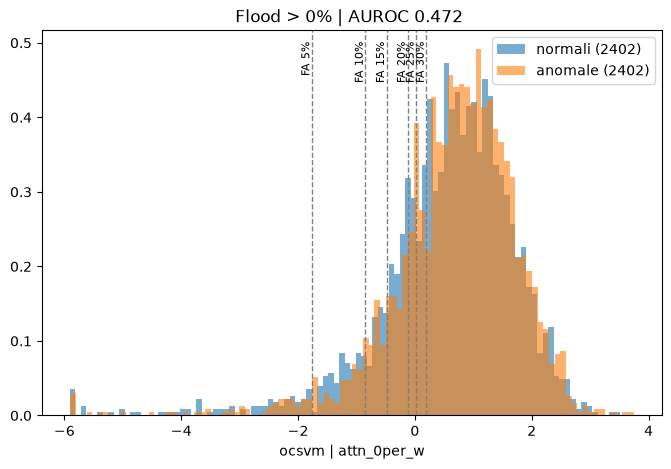

In [ ]:
df = pd.read_csv(f"{RESULTS_DIR}/scores.csv")
score_normal = df[df.label == 0]['score']
score_anom = df[df.label == 1]['score']

lo, hi = np.quantile(df.score, [0.005, 0.995])                   
bins = np.linspace(lo, hi, 100)

plt.figure(figsize=(8, 5))
plt.hist(score_normal, bins=100, alpha=0.6, density=True, label=f"normali ({len(score_normal)})")
plt.hist(score_anom, bins=100, alpha=0.6, density=True, label=f"anomale ({len(score_anom)})")
for nome, r in results['rules'].items():                         
    if lo <= r["soglia"] <= hi:
        plt.axvline(x=r["soglia"], color='gray', linestyle='--', linewidth=1)
        plt.text(r["soglia"], plt.ylim()[1] * 0.97, nome.split("(")[-1].rstrip(")"), rotation=90, va="top", ha="right", fontsize=8)   
plt.xlabel(f"ocsvm | {job_name}")
plt.legend()
plt.title(f"Flood > {results['min_flood_area']:.0f}% | AUROC {results['auroc']:.3f} ")
plt.show()

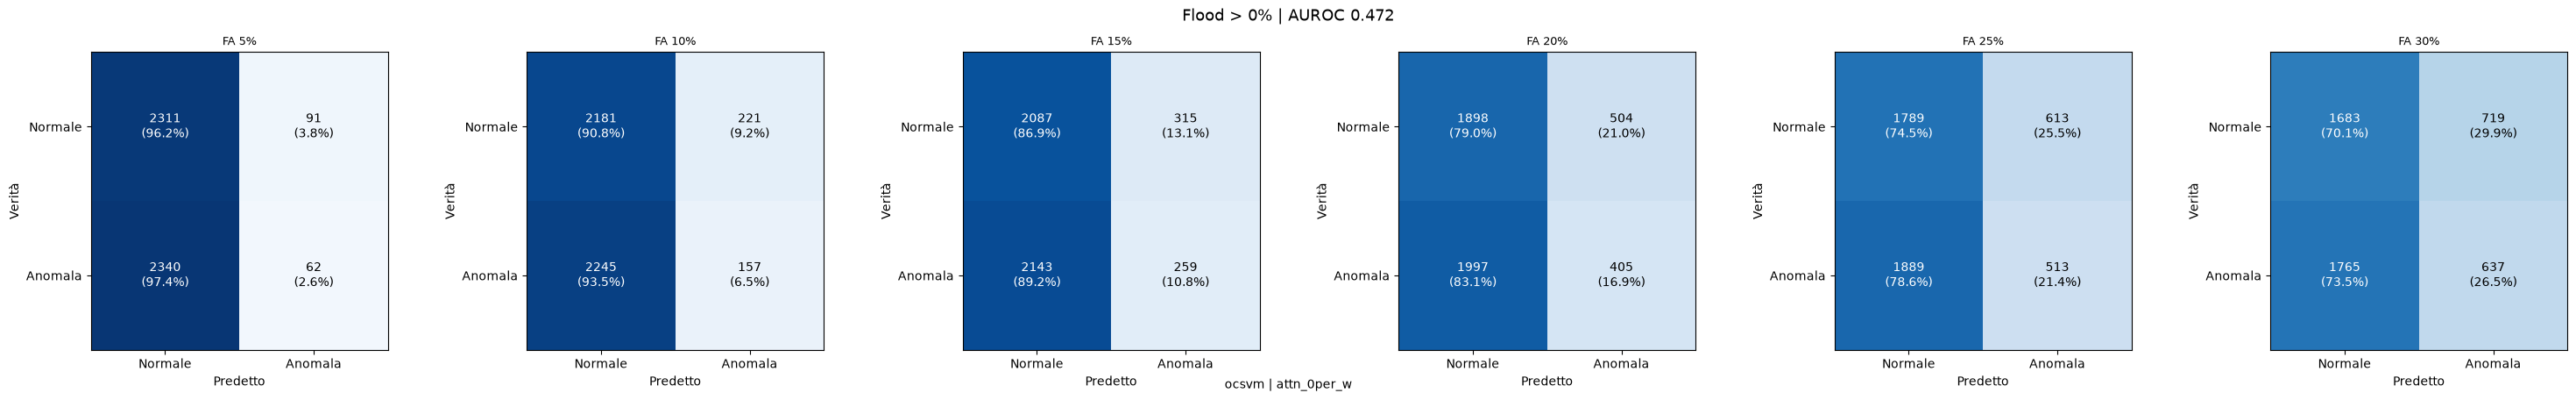

In [ ]:
rules = results['rules']
fig, axes = plt.subplots(1, len(rules), figsize=(5 * len(rules), 4.5), squeeze=False)

for ax, (nome, r) in zip(axes[0], rules.items()):
    mat = np.array([[r["TN"], r["FP"]],
                     [r["FN"], r["TP"]]])
    mat_pct = mat / mat.sum(axis=1, keepdims=True) * 100

    im = ax.imshow(mat_pct, cmap="Blues", vmin=0, vmax=100)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["Normale", "Anomala"])
    ax.set_yticks([0, 1]); ax.set_yticklabels(["Normale", "Anomala"])
    ax.set_xlabel("Predetto"); ax.set_ylabel("Verità")
    ax.set_title(nome, fontsize=9)

    for i in range(2):
        for j in range(2):
            color = "white" if mat_pct[i, j] > 55 else "black"
            ax.text(j, i, f"{int(mat[i, j])}\n({mat_pct[i, j]:.1f}%)",
                    ha="center", va="center", color=color, fontsize=10)

fig.suptitle(f"Flood > {results['min_flood_area']:.0f}% | AUROC {results['auroc']:.3f}", fontsize=13)
fig.text(0.5, 0.01, f"ocsvm | {job_name}", ha="center", va="bottom", fontsize=10)              

plt.tight_layout()
plt.show()